# Energy data quality and same-time estimation: revised analysis

This is the revised analysis. `final.ipynb` and `household_power_consumption.txt` remain preserved source artifacts. The primary modeling baseline uses **observed-only** records. A separate sensitivity analysis explicitly opts into bounded, retrospective short-gap interpolation.

The five-minute cap is **provisional and has not met field-specific acceptance tolerances**. The masking experiment supports comparison of reconstruction methods on observed windows; it cannot prove real missing-period behavior. Interpolation uses a future endpoint and does not support a live forecasting claim. All computation uses free local tools.

Implementation: `scripts/revised_analysis.py`. Evidence and exports: `reports/revised_analysis/`. Run all cells in a fresh kernel, or use `python3 scripts/execute_revised_notebook.py` from the project root.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from scripts import revised_analysis as analysis
from scripts.audit_data_quality import FIELDS, file_hash

ROOT = Path.cwd()
assert (ROOT / 'final.ipynb').is_file(), 'Run from the project root.'
OUTPUT = ROOT / 'reports/revised_analysis'
OUTPUT.mkdir(parents=True, exist_ok=True)
original_hashes = {name: file_hash(ROOT / name) for name in ['final.ipynb', 'household_power_consumption.txt']}
pd.set_option('display.max_columns', 25)
RUN_RETROSPECTIVE_SENSITIVITY = True  # Explicit opt-in for this comparison; False disables all fills.
print('Chronological split:', analysis.SPLIT)
print('Optional retrospective sensitivity enabled:', RUN_RETROSPECTIVE_SENSITIVITY)

Chronological split: 2010-01-01 00:00:00
Optional retrospective sensitivity enabled: True


## 1. Completed audit, MySQL reconciliation, and masking evidence

The following evidence was produced previously. This notebook validates its source and query hashes rather than requiring a live MySQL server or credentials. Data-quality exceptions remain in `reports/exceptions.csv`; model alerts are exported separately.

Missing measurement rows are existing records without readings. Absent minute timestamps are missing records in the expected grid. They are separate audit counts. The audit checks reported here do not establish engineering operating limits.

In [2]:
audit, mysql, masking = analysis.verify_existing_evidence(ROOT)
assert original_hashes['household_power_consumption.txt'] == audit['source_sha256']
assert original_hashes['final.ipynb'] == masking['notebook_sha256']
display(pd.Series(audit['counts'], name='Python audit count').to_frame())
display(pd.Series(mysql['reconciliation'], name='MySQL check').to_frame())
mask_metrics = pd.read_csv(ROOT / 'reports/missing_data_evaluation/metrics.csv')
display(mask_metrics.query("partition == 'holdout' and gap_minutes == 5")[[
    'measurement', 'method', 'n_windows', 'n_masked_readings', 'mae', 'rmse', 'rmse_over_sd', 'p99_abs_error'
]])

,Python audit count
source_rows,2075259
duplicate_rows,0
duplicate_timestamps,0
invalid_timestamps,0
off_minute_timestamps,0
missing_measurement_rows,25979
all_measurements_missing_rows,25979
missing_measurement_cells,181853
invalid_numeric_cells,0
negative_cells,0


,MySQL check
totals_match,True
every_run_matches,True
every_month_matches,True
exception_count_matches,True
python_artifacts_unchanged,True


,measurement,method,n_windows,n_masked_readings,mae,rmse,rmse_over_sd,p99_abs_error
98,Global_active_power,time_linear,3200,16000,0.104709,0.243033,0.255969,1.129010
99,Global_reactive_power,time_linear,3200,16000,0.031542,0.052037,0.458227,0.176670
100,Voltage,time_linear,3200,16000,0.493728,0.663094,0.227398,2.023350
101,Global_intensity,time_linear,3200,16000,0.462352,1.041933,0.261737,4.700333
102,Sub_metering_1,time_linear,3200,16000,0.316490,2.238437,0.399467,12.000000
103,Sub_metering_2,time_linear,3200,16000,0.365542,1.682013,0.323759,9.000000
104,Sub_metering_3,time_linear,3200,16000,0.961156,1.950459,0.223148,9.000000
105,Global_active_power,forward_fill,3200,16000,0.147526,0.366213,0.385705,1.938200
106,Global_reactive_power,forward_fill,3200,16000,0.045169,0.081473,0.717436,0.282000
107,Voltage,forward_fill,3200,16000,0.697339,0.959869,0.329172,3.030100


## 2. Preserve original values and apply an optional bounded policy

`original_measurements` is never overwritten. Both policy objects retain original measurements, original missing/invalid flags, separate analysis values, and per-cell imputation flags. Source row IDs are one-based data-record numbers, excluding the header.

A row-level missing run is the complete consecutive span in which any measurement is missing. Fill a run only if its **whole length is at most five minutes**, all internal timestamps are consecutive valid minutes, and both immediate endpoints are fully observed and valid. Leading/trailing gaps, longer runs, invalid endpoints, and runs crossing the train/test boundary remain missing. A missing field may use valid observed anchors inside an eligible partial-field run; existing observed measurements are never changed. There is no global `interpolate(limit=5)` call that could partially fill longer runs.

In [3]:
original_measurements, timestamps, _ = analysis.load_source(ROOT)
primary = analysis.bounded_policy(original_measurements, timestamps, enabled=False)
sensitivity = analysis.bounded_policy(
    original_measurements, timestamps, enabled=RUN_RETROSPECTIVE_SENSITIVITY, max_minutes=5
)
policies = {'observed_only': primary, 'short_gap_sensitivity': sensitivity}
assert int(primary.was_missing.any(axis=1).sum()) == audit['counts']['missing_measurement_rows']
assert not primary.was_imputed.to_numpy().any()
audit_runs = pd.read_csv(ROOT / 'reports/missing_runs.csv')
assert len(sensitivity.runs) == len(audit_runs)
assert np.array_equal(sensitivity.runs.number_of_missing_readings, audit_runs.number_of_missing_readings)
assert sensitivity.runs.loc[sensitivity.runs.number_of_missing_readings > 5, 'imputed_values'].eq(0).all()
retention = analysis.retention_table(policies)
retention.to_csv(OUTPUT / 'retention_counts.csv', index=False)
analysis.export_policy(sensitivity, OUTPUT)
display(retention)
display(sensitivity.runs.groupby(['eligible', 'reason'], dropna=False).agg(
    runs=('missing_run_id', 'size'), missing_records=('number_of_missing_readings', 'sum'),
    imputed_values=('imputed_values', 'sum')
))

,scenario,partition,source_records,retained_records,retained_observed_records,imputed_records,imputed_values,excluded_records,original_missing_records,invalid_measurement_records
0,observed_only,all,2075259,2049280,2049280,0,0,25979,25979,0
1,observed_only,train_period,1600236,1591886,1591886,0,0,8350,8350,0
2,observed_only,test_period,475023,457394,457394,0,0,17629,17629,0
3,short_gap_sensitivity,all,2075259,2049356,2049280,76,532,25903,25979,0
4,short_gap_sensitivity,train_period,1600236,1591952,1591886,66,462,8284,8350,0
5,short_gap_sensitivity,test_period,475023,457404,457394,10,70,17619,17629,0


,,runs,missing_records,imputed_values
eligible,reason,,,
False,longer_than_cap,16,25903,0
True,eligible,55,76,532


In [4]:
imputed_ids = sensitivity.original.index[sensitivity.was_imputed.any(axis=1)]
example = imputed_ids[:5]
display(pd.DataFrame({
    'timestamp': timestamps.loc[example],
    'original_active_power': original_measurements.loc[example, 'Global_active_power'],
    'analysis_active_power': sensitivity.values.loc[example, 'Global_active_power'],
    'was_missing': sensitivity.was_missing.loc[example, 'Global_active_power'],
    'was_imputed': sensitivity.was_imputed.loc[example, 'Global_active_power'],
    'missing_run_id': sensitivity.run_ids.loc[example],
}))
print('All seven original measurement columns and all per-cell flags remain available in each policy object.')
print('Sparse provenance export includes every source row with a missing/invalid measurement or timestamp; unaffected rows have all flags False.')

,timestamp,original_active_power,analysis_active_power,was_missing,was_imputed,missing_run_id
source_row_id,,,,,,
6840,2006-12-21 11:23:00,NaN,0.244667,True,True,1
6841,2006-12-21 11:24:00,NaN,0.245333,True,True,1
19725,2006-12-30 10:08:00,NaN,6.417333,True,True,2
19726,2006-12-30 10:09:00,NaN,6.616667,True,True,2
41833,2007-01-14 18:36:00,NaN,3.213000,True,True,3


All seven original measurement columns and all per-cell flags remain available in each policy object.
Sparse provenance export includes every source row with a missing/invalid measurement or timestamp; unaffected rows have all flags False.


## 3. Modeling design and retained data

Training periods are strictly earlier than January 1, 2010; all test periods are later. To limit local compute, Random Forest and its simple baselines use the same seeded sample of up to 60,000 observed training rows. Isolation Forest uses up to 32,000. The sensitivity fits retain those exact samples and add eligible short-gap-imputed training records; source IDs are exported.

Both regression scenarios are evaluated on **all common observed 2010 targets**, excluding imputed test targets from metrics. Isolation Forest scores each scenario's retained 2010 records, reporting common-observed and additional imputed counts separately. The holdout ends at the dataset's actual end in November 2010.

Calendar features are deterministic categories. Learned one-hot encoding, regression coefficients, means, and forests are fitted on training data only. No future endpoint may cross the train/test split. Serial dependence within this single household remains a limitation.

In [5]:
frames = {name: analysis.features(policy) for name, policy in policies.items()}
display(pd.DataFrame({name: {'retained_feature_rows': len(frame), 'earlier_rows': int((timestamps.loc[frame.index] < analysis.SPLIT).sum()),
                           'later_rows': int((timestamps.loc[frame.index] >= analysis.SPLIT).sum())}
                      for name, frame in frames.items()}).T)
print('Random Forest settings:', analysis.RF_SETTINGS)
print('Isolation Forest settings:', analysis.IF_SETTINGS)
print('RF numeric predictors:', analysis.RF_NUMERIC)
print('RF categorical calendar predictors:', analysis.RF_CALENDAR)

,retained_feature_rows,earlier_rows,later_rows
observed_only,2049280,1591886,457394
short_gap_sensitivity,2049356,1591952,457404


Random Forest settings: {'n_estimators': 80, 'max_depth': 20, 'random_state': 42, 'n_jobs': 2}
Isolation Forest settings: {'n_estimators': 150, 'max_samples': 256, 'contamination': 0.02, 'max_features': 1.0, 'bootstrap': False, 'random_state': 42, 'n_jobs': 2}
RF numeric predictors: ['Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
RF categorical calendar predictors: ['Hour', 'DayOfWeek', 'Month', 'Is_Weekend']


## 4. Random Forest: same-time power estimation

The target is `Global_active_power` at the **same timestamp** as the predictor readings. Current intensity and the other meter readings are physically related to power, making this a strong-coupling estimation task, not future forecasting. Compare Random Forest with a training-mean constant and a simple linear model using same-time current intensity. No imputed value is treated as an observed test target.

In [6]:
regression_metrics, regression_sensitivity, regression_training = analysis.run_regression(policies, frames, OUTPUT)
display(regression_metrics)
display(pd.Series(regression_sensitivity, name='Change on common observed test records').to_frame())

Regression completed: observed_only (60,000 train; 457,394 observed test targets)


Regression completed: short_gap_sensitivity (60,066 train; 457,394 observed test targets)


,scenario,estimator,train_records,train_imputed_records,n_observed_targets,mae,rmse,r2
0,observed_only,training_mean,60000,0,457394,0.742154,0.933906,-0.001933
1,observed_only,intensity_linear,60000,0,457394,0.034893,0.049704,0.997162
2,observed_only,random_forest,60000,0,457394,0.021528,0.036277,0.998488
3,short_gap_sensitivity,training_mean,60066,66,457394,0.742285,0.933944,-0.002015
4,short_gap_sensitivity,intensity_linear,60066,66,457394,0.034897,0.049706,0.997162
5,short_gap_sensitivity,random_forest,60066,66,457394,0.021543,0.036338,0.998483


,Change on common observed test records
common_observed_test_records,457394.000000
mean_absolute_change_in_estimate,0.002965
max_absolute_change_in_estimate,0.104369


## 5. Isolation Forest: matched alert and proxy thresholds

Each scenario fits **one** model on its earlier-period training sample, using the settings shown above. Its training-derived `offset_` is then frozen. Real holdout alerts and the synthetic proxy use the exact same fitted model and strict `score_samples < offset_` rule. No separate high-contamination evaluation model or post-evaluation refit is used.

The proxy contains 10,000 observed holdout records plus 10,000 independently perturbed copies: active power ×1.7–2.8, intensity ×1.4–2.3, voltage ×0.84–0.95, and sub-metering 3 ×1.3–2.0. These are synthetic stress patterns, not validated fault mechanisms. Original proxy records have unknown real labels and are assumed negative only to compute proxy precision. Precision is conditional on the artificial 50% injection prevalence. Real model alerts remain **unlabeled records for review**; they are not confirmed faults or theft.

In [7]:
isolation_metrics, isolation_sensitivity, isolation_training = analysis.run_isolation(policies, frames, OUTPUT)
display(isolation_metrics)
display(pd.Series(isolation_sensitivity, name='Common observed holdout decisions').to_frame())
alerts = pd.read_csv(OUTPUT / 'model_alerts.csv')
assert (alerts.score < alerts.threshold).all()
display(alerts.head())
print('Model alerts:', OUTPUT / 'model_alerts.csv')
print('Data-quality exceptions remain separate:', ROOT / 'reports/exceptions.csv')

Isolation Forest completed: observed_only (4,854 later-period unlabeled alerts)


Isolation Forest completed: short_gap_sensitivity (5,579 later-period unlabeled alerts)


,scenario,train_records,train_imputed_records,threshold,test_records,test_imputed_records,real_alert_count,common_observed_alert_count,common_observed_test_records,common_observed_alert_rate,imputed_test_alert_count,proxy_original_records,proxy_injected_records,proxy_alert_count,synthetic_true_positive_count,assumed_negative_alert_count,synthetic_recall,synthetic_precision
0,observed_only,32000,0,-0.652676,457394,0,4854,4854,457394,0.010612,0,10000,10000,1126,1024,102,0.1024,0.909414
1,short_gap_sensitivity,32066,66,-0.656737,457404,10,5579,5579,457394,0.012197,0,10000,10000,971,855,116,0.0855,0.880536


,Common observed holdout decisions
common_observed_test_records,457394
alerts_in_both,4368
primary_only_alerts,486
sensitivity_only_alerts,1211
changed_alert_decisions,1697


,source_row_id,timestamp,scenario,score,threshold,decision_score,threshold_rule,was_imputed_any,was_missing_originally_any,missing_run_id,was_imputed__Global_active_power,was_imputed__Global_reactive_power,was_imputed__Voltage,was_imputed__Global_intensity,was_imputed__Sub_metering_1,was_imputed__Sub_metering_2,was_imputed__Sub_metering_3
0,1602757,2010-01-02 18:00:00,observed_only,-0.695543,-0.652676,-0.042867,score < threshold,False,False,NaN,False,False,False,False,False,False,False
1,1602758,2010-01-02 18:01:00,observed_only,-0.696864,-0.652676,-0.044188,score < threshold,False,False,NaN,False,False,False,False,False,False,False
2,1602759,2010-01-02 18:02:00,observed_only,-0.682513,-0.652676,-0.029837,score < threshold,False,False,NaN,False,False,False,False,False,False,False
3,1602760,2010-01-02 18:03:00,observed_only,-0.685116,-0.652676,-0.032439,score < threshold,False,False,NaN,False,False,False,False,False,False,False
4,1602761,2010-01-02 18:04:00,observed_only,-0.688084,-0.652676,-0.035408,score < threshold,False,False,NaN,False,False,False,False,False,False,False


Model alerts: /Users/niahyellegreen/Documents/PersonalProjects/Anomaly-Detection-in-High-Frequency-Energy-Data/reports/revised_analysis/model_alerts.csv
Data-quality exceptions remain separate: /Users/niahyellegreen/Documents/PersonalProjects/Anomaly-Detection-in-High-Frequency-Energy-Data/reports/exceptions.csv


## 6. Comparison charts and reproducible findings

Sensitivity differences reflect both the added imputed records and changes in tree sampling. They do not isolate a causal benefit from interpolation. Missing-period behavior, field-specific acceptance tolerances, domain labels, and real-world alert precision remain unresolved. Retain the observed-only baseline as the main result.

Matplotlib is building the font cache; this may take a moment.


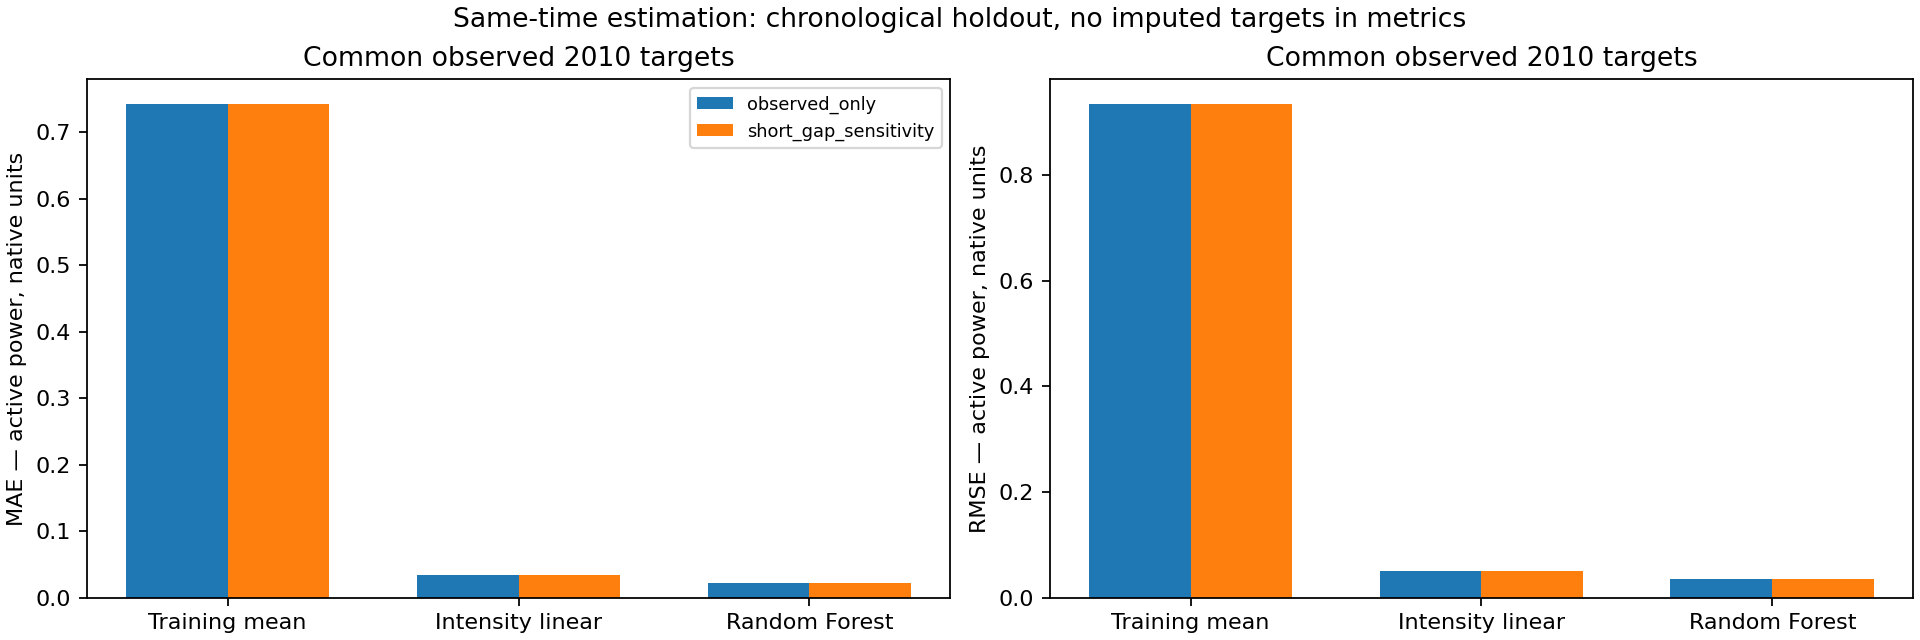

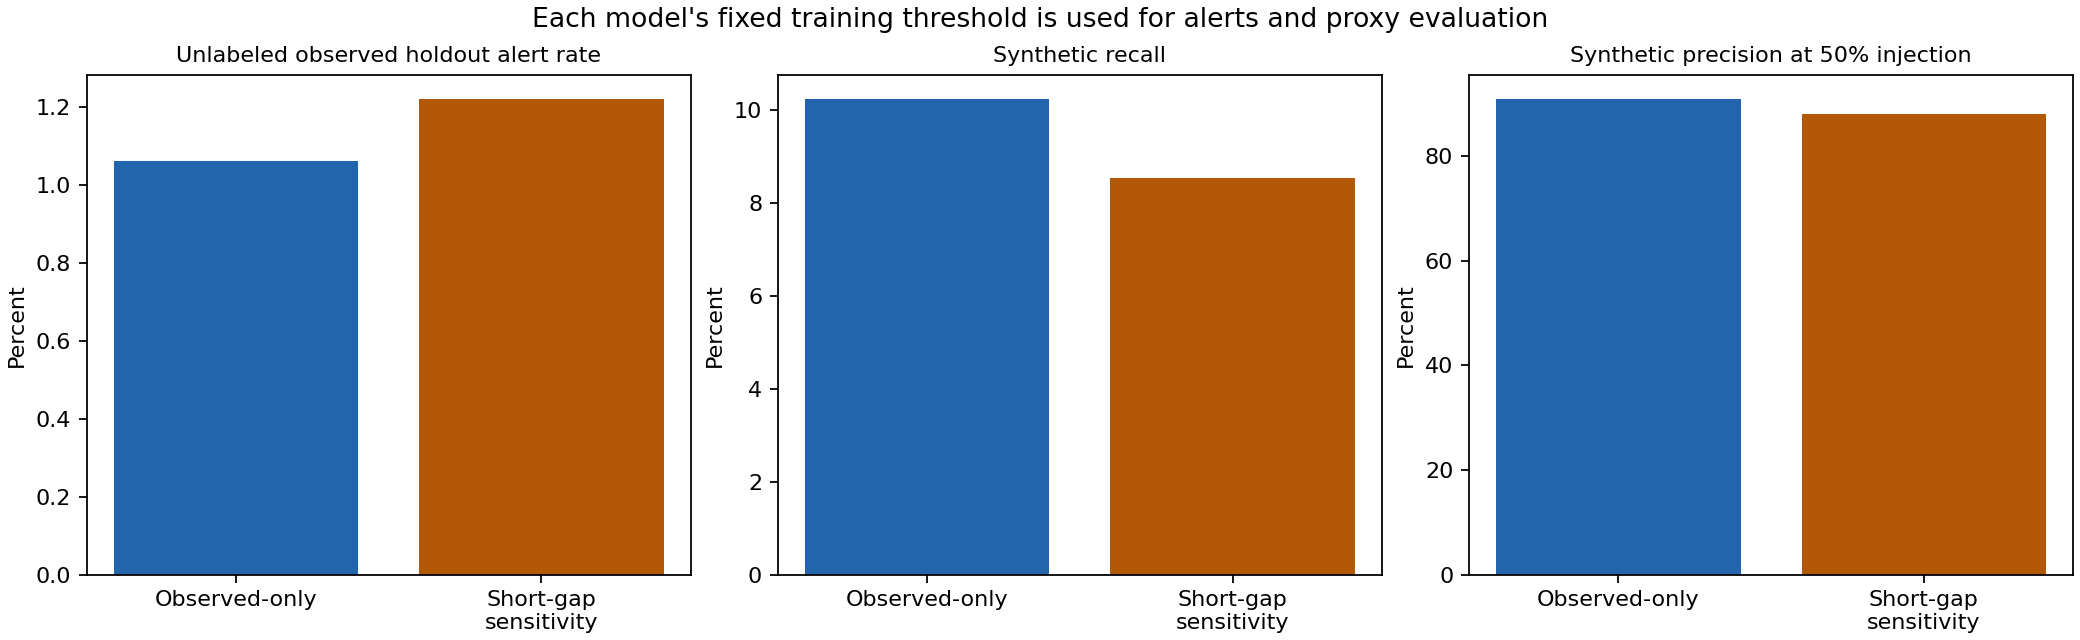

**Measured interpretation.** Primary Random Forest MAE is 0.021528 and RMSE 0.036277 on observed later-period targets. Its high R² reflects same-time coupled meter signals, not future forecasting. Sensitivity MAE is 0.021543; this comparison does not approve interpolation.

The primary Isolation Forest recovered **1,024 of 10,000 synthetic injections (10.24% recall)** at its unchanged alert threshold. This is limited recovery of these artificial patterns. Proxy precision (90.94%) assumes negative original records and 50% injection prevalence; it is not real-fault precision. The 4,854 real-data alerts are unlabeled.

Keep observed-only results primary. The five-minute retrospective cap remains provisional and has not met field-specific acceptance tolerances. [Full measured findings](reports/revised_analysis/findings.md) include sensitivity counts, thresholds, limitations, and links to each export.

In [8]:
sensitivity_results = {'regression': regression_sensitivity, 'isolation_forest': isolation_sensitivity}
analysis.plot_models(regression_metrics, isolation_metrics, OUTPUT)
analysis.finalize(ROOT, policies, retention, regression_metrics, isolation_metrics,
                  sensitivity_results, regression_training + isolation_training, original_hashes)
display(Image(filename=str(OUTPUT / 'regression_comparison.png')))
display(Image(filename=str(OUTPUT / 'isolation_comparison.png')))
primary_rf = regression_metrics.query("scenario == 'observed_only' and estimator == 'random_forest'").iloc[0]
sensitivity_rf = regression_metrics.query("scenario == 'short_gap_sensitivity' and estimator == 'random_forest'").iloc[0]
primary_if = isolation_metrics.query("scenario == 'observed_only'").iloc[0]
display(Markdown(f'''**Measured interpretation.** Primary Random Forest MAE is {primary_rf.mae:.6f} and RMSE {primary_rf.rmse:.6f} on observed later-period targets. Its high R² reflects same-time coupled meter signals, not future forecasting. Sensitivity MAE is {sensitivity_rf.mae:.6f}; this comparison does not approve interpolation.

The primary Isolation Forest recovered **{int(primary_if.synthetic_true_positive_count):,} of {int(primary_if.proxy_injected_records):,} synthetic injections ({primary_if.synthetic_recall:.2%} recall)** at its unchanged alert threshold. This is limited recovery of these artificial patterns. Proxy precision ({primary_if.synthetic_precision:.2%}) assumes negative original records and 50% injection prevalence; it is not real-fault precision. The {int(primary_if.real_alert_count):,} real-data alerts are unlabeled.

Keep observed-only results primary. The five-minute retrospective cap remains provisional and has not met field-specific acceptance tolerances. [Full measured findings](reports/revised_analysis/findings.md) include sensitivity counts, thresholds, limitations, and links to each export.'''))

## 7. Preservation and output checks

`measurement_policy_records.csv` preserves original numeric values, proposed analysis values, and per-field missing/invalid/imputed flags for every affected source record. The raw file retains exact original text tokens. Unaffected source records have all flags False. `missing_run_treatment.csv` documents every run's eligibility and reason.

`model_alerts.csv` contains scenario, source identifiers, timestamps, score, frozen threshold, decision score, original-missing status, run ID where applicable, and per-field imputation status. Its rows are only unlabeled model alerts from retained holdout records. Synthetic proxy evaluations are exported to a different file. The original audit and its exception CSV are not rewritten.

In [9]:
assert all(file_hash(ROOT / name) == digest for name, digest in original_hashes.items())
print('Original notebook and raw dataset hashes unchanged.')
display(pd.DataFrame({'artifact': [path.name for path in sorted(OUTPUT.iterdir()) if path.is_file()]}))

Original notebook and raw dataset hashes unchanged.


,artifact
0,findings.md
1,isolation_comparison.png
2,isolation_forest_metrics.csv
3,measurement_policy_records.csv
4,missing_run_treatment.csv
5,model_alerts.csv
6,notebook_execution.json
7,regression_comparison.png
8,regression_metrics.csv
9,regression_metrics_by_month.csv
